# Assignment 55 — Week 6, Day 5
## Topic: Machine Learning — Time Series Analysis

**Objective:** Complete the exercise on time-series analysis.

**Reference:** https://www.dataquest.io/blog/tutorial-time-series-analysis-with-pandas

A time series is data recorded at regular points in time, such as daily electricity use. Pandas has special tools for dates and times: a **DatetimeIndex** for selecting by date, **resample()** for changing the frequency, and **rolling()** for moving averages.

This notebook follows the Dataquest tutorial using Open Power System Data for Germany (`opsd_germany_daily.csv`, which must be in the same folder): daily electricity consumption, wind and solar production from 2006 to 2017.

**Diagram:** A time series can be thought of as a trend, a seasonal pattern and random noise added together (illustrative data).

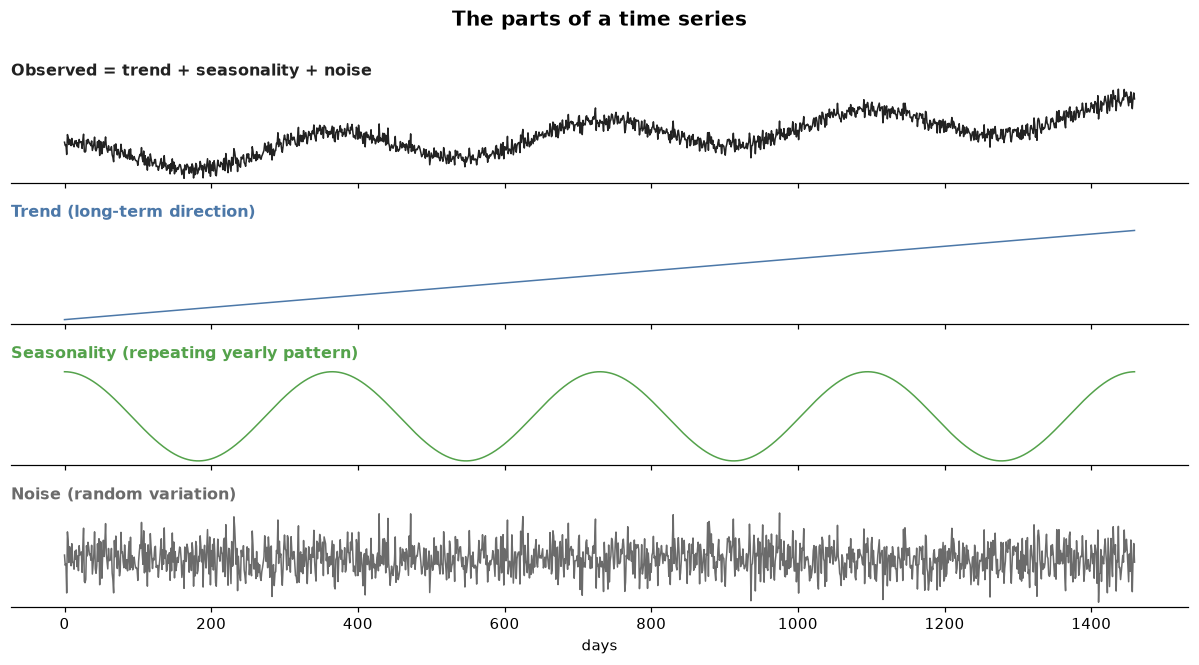

**Pandas time-related data types**

In [1]:
import pandas as pd

print(pd.to_datetime("2018-01-15 3:45pm"))
print(pd.to_datetime("7/8/1952"))
print(pd.to_datetime("7/8/1952", dayfirst=True))
print(pd.to_datetime(["2018-01-05", "7/8/1952", "Oct 10, 1995"], format="mixed"))
print(pd.date_range("1998-03-10", "1998-03-15", freq="D"))

2018-01-15 15:45:00
1952-07-08 00:00:00
1952-08-07 00:00:00
DatetimeIndex(['2018-01-05', '1952-07-08', '1995-10-10'], dtype='datetime64[us]', freq=None)
DatetimeIndex(['1998-03-10', '1998-03-11', '1998-03-12', '1998-03-13',
               '1998-03-14', '1998-03-15'],
              dtype='datetime64[us]', freq='D')


**Explanation:** to_datetime() turns text into Timestamps and understands many formats. dayfirst=True reads 7/8 as 7 August. date_range() creates a regular series of dates.

**Load the OPSD Germany data with a DatetimeIndex**

In [2]:
import pandas as pd

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

opsd_daily["Year"] = opsd_daily.index.year
opsd_daily["Month"] = opsd_daily.index.month
opsd_daily["Weekday Name"] = opsd_daily.index.day_name()

print(opsd_daily.shape)
print(opsd_daily.dtypes)
print(opsd_daily.sample(5, random_state=0))

(4383, 7)
Consumption     float64
Wind            float64
Solar           float64
Wind+Solar      float64
Year              int32
Month             int32
Weekday Name        str
dtype: object
            Consumption    Wind    Solar  Wind+Solar  Year  Month Weekday Name
Date                                                                          
2008-08-23     1152.011     NaN      NaN         NaN  2008      8     Saturday
2013-08-08     1291.984  79.666   93.371     173.037  2013      8     Thursday
2009-08-27     1281.057     NaN      NaN         NaN  2009      8     Thursday
2015-10-02     1391.050  81.229  160.641     241.870  2015     10       Friday
2009-06-02     1201.522     NaN      NaN         NaN  2009      6      Tuesday


**Explanation:** The data has daily electricity consumption, wind and solar power production in Germany (in GWh) from 2006 to 2017. Using Date as the index creates a DatetimeIndex, which makes it easy to add Year, Month and Weekday Name columns.

**Select data by time**

In [3]:
import pandas as pd

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

print(opsd_daily.loc["2017-08-10"])
print(opsd_daily.loc["2014-01-20":"2014-01-22"])
print(opsd_daily.loc["2012-02"].shape)

Consumption    1351.491
Wind            100.274
Solar            71.160
Wind+Solar      171.434
Name: 2017-08-10 00:00:00, dtype: float64
            Consumption    Wind   Solar  Wind+Solar
Date                                               
2014-01-20     1590.687  78.647   6.371      85.018
2014-01-21     1624.806  15.643   5.835      21.478
2014-01-22     1625.155  60.259  11.992      72.251
(29, 4)


**Explanation:** With a DatetimeIndex, loc accepts dates as text. A single date returns one row, a range returns several rows, and a partial date such as '2012-02' returns the whole month.

**Plot the time series**

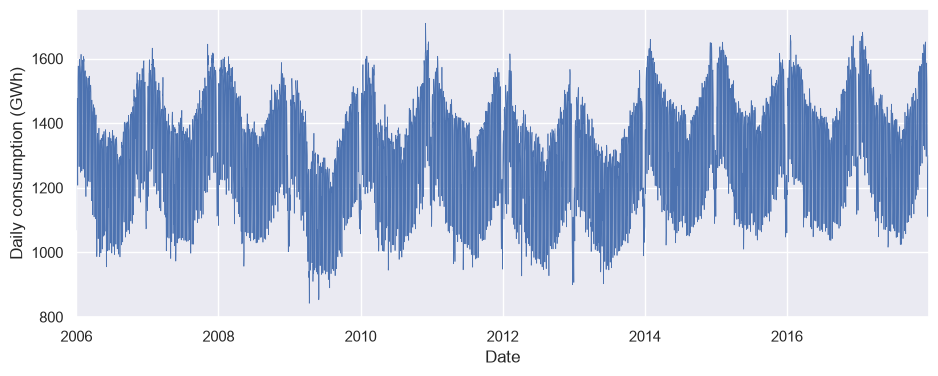

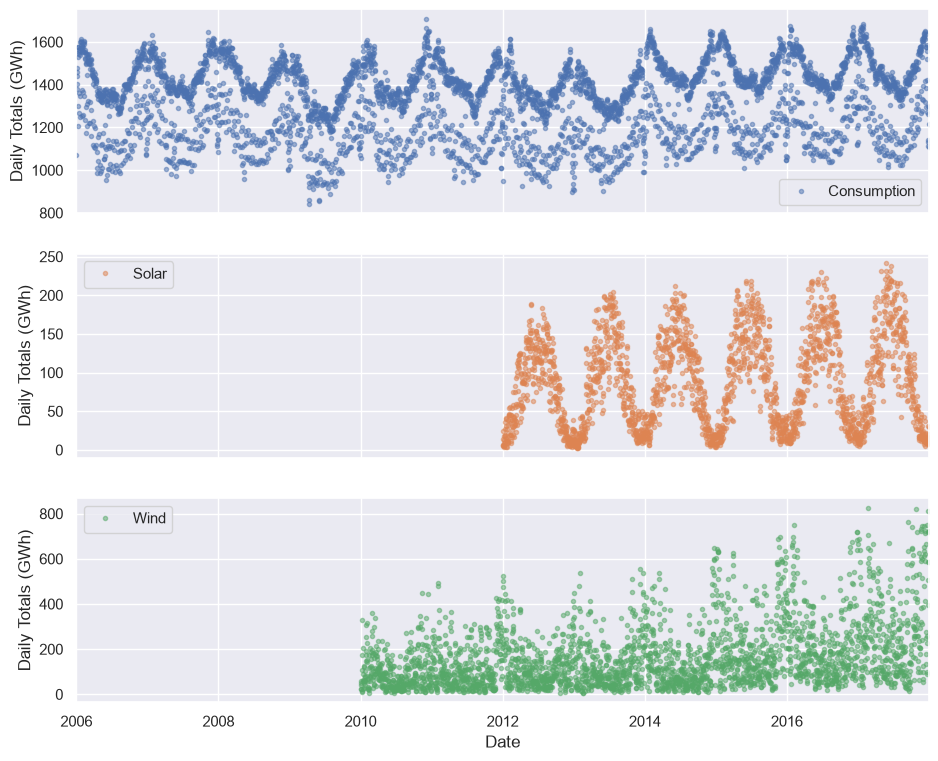

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(rc={"figure.figsize": (11, 4)})

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

opsd_daily["Consumption"].plot(linewidth=0.5)
plt.ylabel("Daily consumption (GWh)")
plt.show()

cols_plot = ["Consumption", "Solar", "Wind"]
axes = opsd_daily[cols_plot].plot(marker=".", alpha=0.5, linestyle="None", figsize=(11, 9), subplots=True)
for ax in axes:
    ax.set_ylabel("Daily Totals (GWh)")
plt.show()

**Explanation:** Consumption is highest in winter and lowest in summer. Solar is highest in summer and wind is highest in winter, and wind production grows over the years.

**Seasonality with box plots**

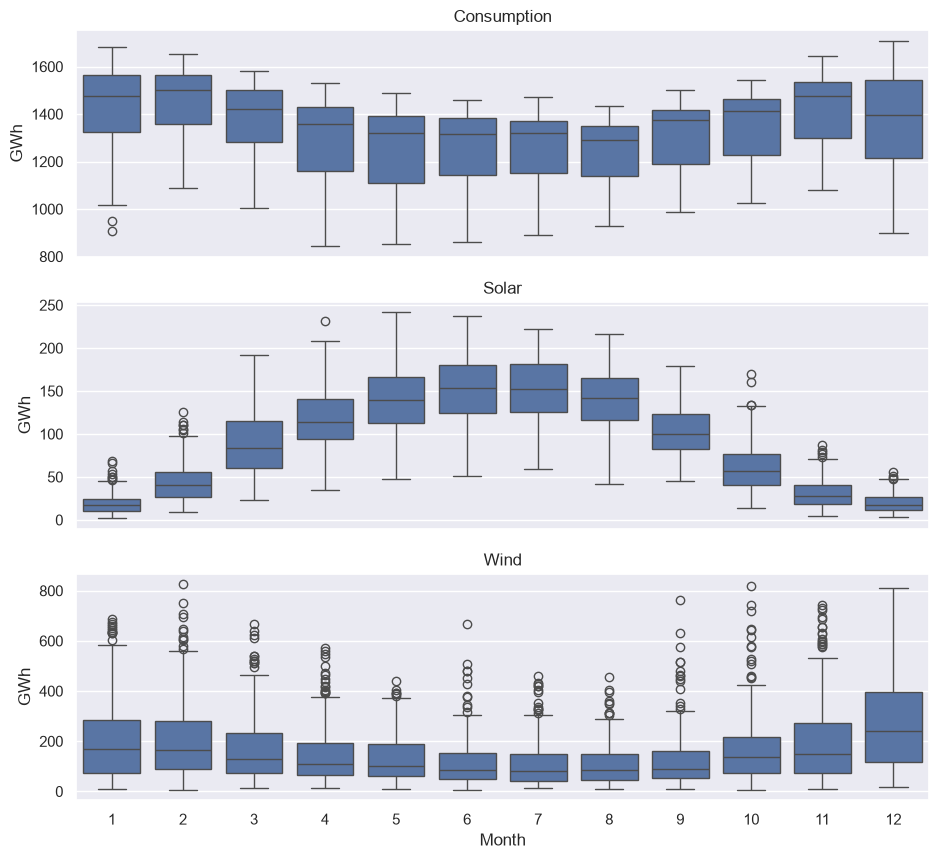

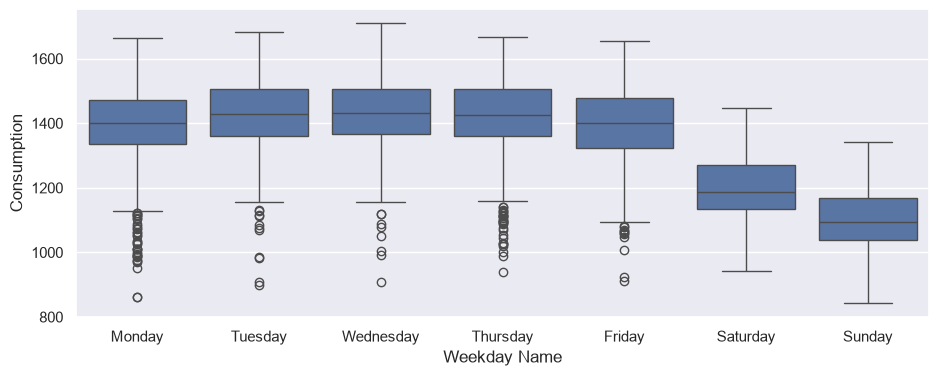

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)
opsd_daily["Month"] = opsd_daily.index.month
opsd_daily["Weekday Name"] = opsd_daily.index.day_name()

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for name, ax in zip(["Consumption", "Solar", "Wind"], axes):
    sns.boxplot(data=opsd_daily, x="Month", y=name, ax=ax)
    ax.set_ylabel("GWh")
    ax.set_title(name)
    if ax != axes[-1]:
        ax.set_xlabel("")
plt.show()

sns.boxplot(data=opsd_daily, x="Weekday Name", y="Consumption",
            order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
plt.show()

**Explanation:** Grouping by month shows the yearly seasonality clearly. Grouping by weekday shows that consumption is much lower on weekends, when most businesses are closed.

**Frequencies**

In [6]:
import pandas as pd

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

times_sample = pd.to_datetime(["2013-02-03", "2013-02-06", "2013-02-08"])
consum_sample = opsd_daily.loc[times_sample, ["Consumption"]].copy()
print(consum_sample)

consum_freq = consum_sample.asfreq("D")
consum_freq["Consumption - Forward Fill"] = consum_sample.asfreq("D", method="ffill")
print(consum_freq)

            Consumption
2013-02-03     1109.639
2013-02-06     1451.449
2013-02-08     1433.098
            Consumption  Consumption - Forward Fill
2013-02-03     1109.639                    1109.639
2013-02-04          NaN                    1109.639
2013-02-05          NaN                    1109.639
2013-02-06     1451.449                    1451.449
2013-02-07          NaN                    1451.449
2013-02-08     1433.098                    1433.098


**Explanation:** asfreq('D') changes the data to a daily frequency. Missing days are filled with NaN, or with the last known value when method='ffill' is used.

**Diagram:** resample() groups the data into larger periods; rolling() averages a moving window.

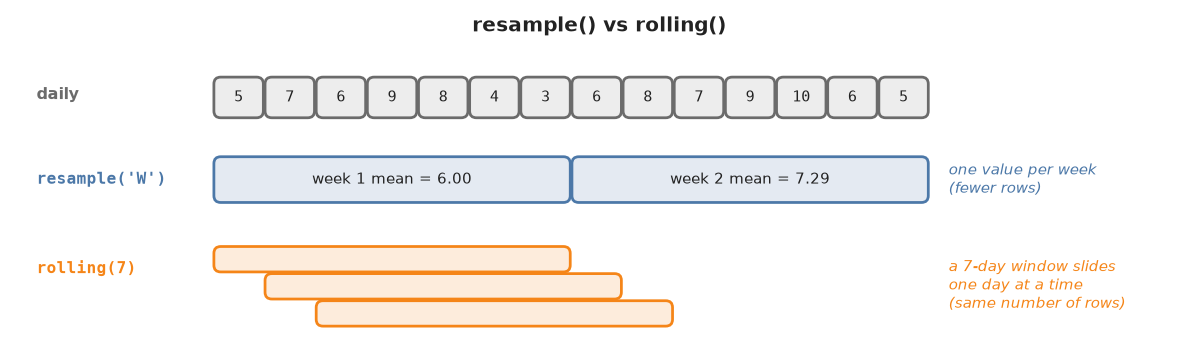

**Resampling to weekly means**

            Consumption  Wind  Solar  Wind+Solar
Date                                            
2006-01-01  1069.184000   NaN    NaN         NaN
2006-01-08  1381.300143   NaN    NaN         NaN
2006-01-15  1486.730286   NaN    NaN         NaN


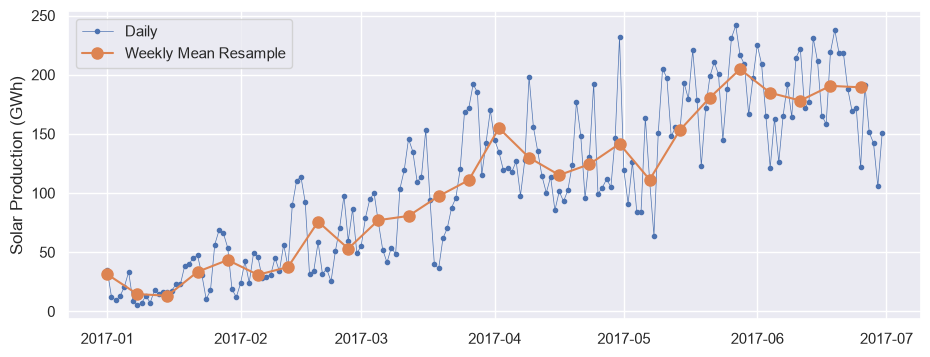

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

data_columns = ["Consumption", "Wind", "Solar", "Wind+Solar"]
opsd_weekly_mean = opsd_daily[data_columns].resample("W").mean()
print(opsd_weekly_mean.head(3))

start, end = "2017-01", "2017-06"
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(opsd_daily.loc[start:end, "Solar"], marker=".", linestyle="-", linewidth=0.5, label="Daily")
ax.plot(opsd_weekly_mean.loc[start:end, "Solar"], marker="o", markersize=8, linestyle="-", label="Weekly Mean Resample")
ax.set_ylabel("Solar Production (GWh)")
ax.legend()
plt.show()

**Explanation:** resample('W').mean() groups the daily data into weeks and averages each week. The weekly line is smoother than the daily line.

**Rolling windows and trends**

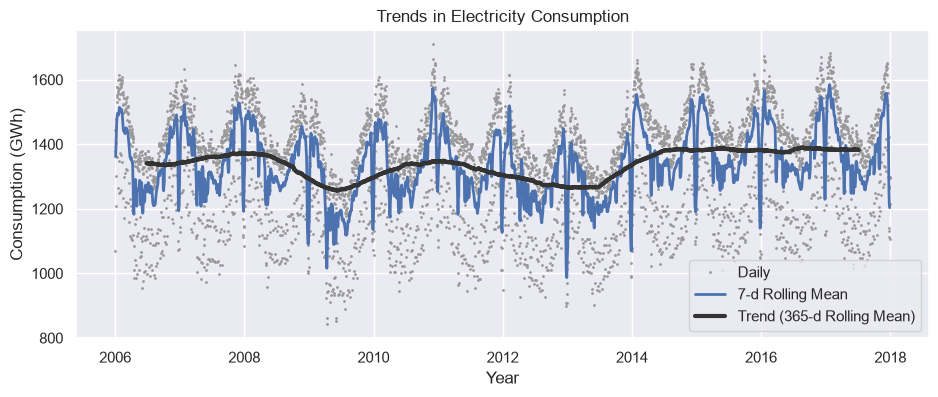

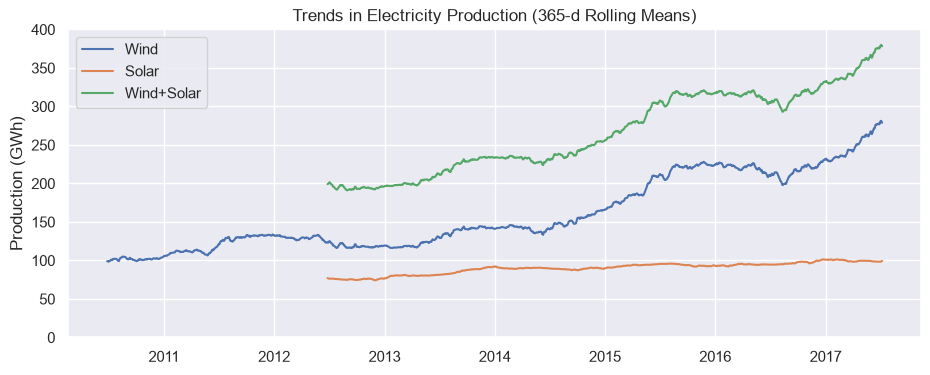

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

opsd_daily = pd.read_csv("opsd_germany_daily.csv", index_col=0, parse_dates=True)

data_columns = ["Consumption", "Wind", "Solar", "Wind+Solar"]
opsd_7d = opsd_daily[data_columns].rolling(7, center=True).mean()
opsd_365d = opsd_daily[data_columns].rolling(window=365, center=True, min_periods=360).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(opsd_daily["Consumption"], marker=".", markersize=2, color="0.6", linestyle="None", label="Daily")
ax.plot(opsd_7d["Consumption"], linewidth=2, label="7-d Rolling Mean")
ax.plot(opsd_365d["Consumption"], color="0.2", linewidth=3, label="Trend (365-d Rolling Mean)")
ax.set_xlabel("Year")
ax.set_ylabel("Consumption (GWh)")
ax.set_title("Trends in Electricity Consumption")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
for nm in ["Wind", "Solar", "Wind+Solar"]:
    ax.plot(opsd_365d[nm], label=nm)
ax.set_ylim(0, 400)
ax.set_ylabel("Production (GWh)")
ax.set_title("Trends in Electricity Production (365-d Rolling Means)")
ax.legend()
plt.show()

**Explanation:** A rolling mean averages a moving window of days. The 7-day window smooths out the weekly pattern, and the 365-day window removes the seasons to show the long-term trend. Consumption stays fairly flat, while wind and solar production rise steadily.

## Observation

- Pandas handles dates with Timestamp, DatetimeIndex and to_datetime().
- A DatetimeIndex lets data be selected by a date, a month or a date range with loc.
- Box plots by month and by weekday reveal yearly and weekly seasonality.
- asfreq() changes the frequency, resample() aggregates into larger periods, and rolling() smooths with a moving window.
- German electricity consumption is seasonal and lower on weekends, while wind and solar production grew strongly over the years.

## Conclusion

Time series analysis separates long-term trends from repeating patterns and noise. Pandas' date tools make it straightforward to select, resample and smooth time-based data before modelling or forecasting.